# Experiment 15: Iris Flower Classification using Naive Bayes
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **Iris Flower Classification** using the **Naive Bayes** classifier.

Gaussian Naive Bayes assumes each feature follows a normal distribution within each class and that features are conditionally independent.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

nb = GaussianNB().fit(X_train, y_train)
pd.DataFrame(nb.theta_, index=iris.target_names, columns=iris.feature_names).round(3)   # class-wise feature means

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,4.985,3.415,1.477,0.255
versicolor,5.930,2.750,4.252,1.320
virginica,6.610,2.980,5.580,2.040


Test accuracy: 0.9667
5-fold CV accuracy: 0.9533

Class priors: {'setosa': 0.333, 'versicolor': 0.333, 'virginica': 0.333}

               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



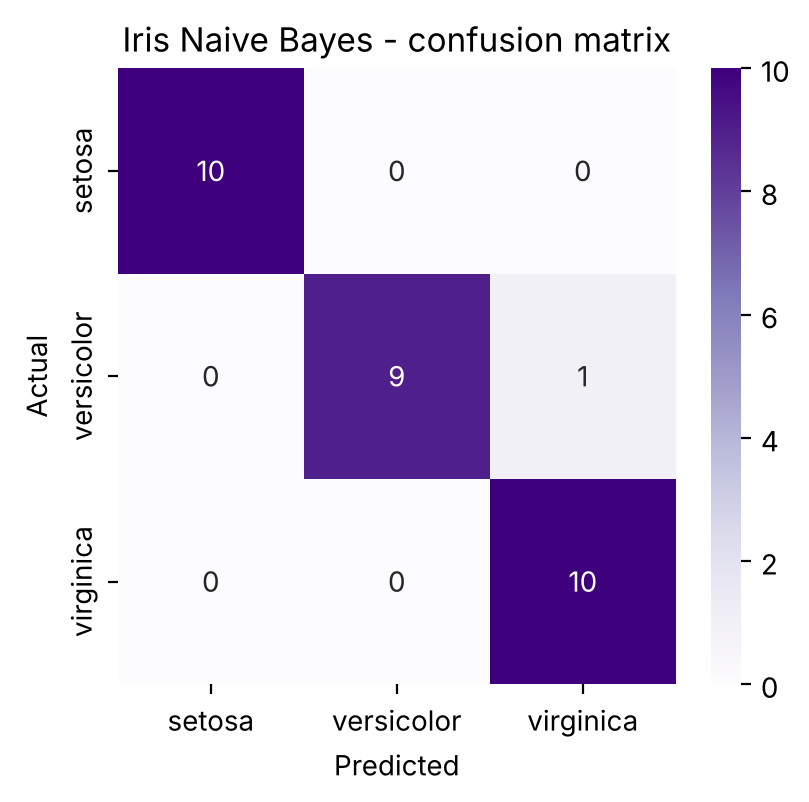

In [2]:
pred = nb.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, pred), 4))
print('5-fold CV accuracy:', round(cross_val_score(GaussianNB(), X, y, cv=5).mean(), 4))
print('\nClass priors:', {str(k): round(float(v), 3) for k, v in zip(iris.target_names, nb.class_prior_)})
print('\n', classification_report(y_test, pred, target_names=iris.target_names))

plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Purples',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Iris Naive Bayes - confusion matrix'); plt.show()

In [3]:
# Posterior probabilities for new flowers
new = np.array([[5.0, 3.4, 1.5, 0.2], [6.3, 2.8, 4.9, 1.6], [7.1, 3.0, 5.9, 2.1]])
proba = nb.predict_proba(new)
out = pd.DataFrame(proba, columns=iris.target_names).round(4)
out['Predicted'] = [iris.target_names[i] for i in nb.predict(new)]
out

,setosa,versicolor,virginica,Predicted
0,1.0,0.0000,0.0000,setosa
1,0.0,0.7076,0.2924,versicolor
2,0.0,0.0000,1.0000,virginica


## Result
Gaussian Naive Bayes reaches about 93-97 % accuracy on Iris. The posterior probabilities show high confidence for `setosa` and some overlap between `versicolor` and `virginica`.